# AIGC 5005 · Module 05 · Part 5
## Metrics beyond accuracy

Companion notebook for the matching part of the Module 05 learning content. Read each explanation, **predict** what the next cell will show, run it, and compare. Change values and run again; you cannot break anything.

**Kernel:** choose the `module05-sklearn` conda environment (top right in VS Code). To make it: `conda create -n module05-sklearn python=3.11 ipykernel`, then `conda activate module05-sklearn` and `pip install -r requirements.txt`. `churn_pipeline.py` and `customers.py` in this folder are shared modules.

In [1]:
from churn_pipeline import build_pipeline, load_split

X, y, X_train, X_test, y_train, y_test = load_split()

## A baseline to beat
`DummyClassifier` always predicts the most common class.

In [2]:
from sklearn.dummy import DummyClassifier

baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
pipe = build_pipeline().fit(X_train, y_train)
print("baseline", round(baseline.score(X_test, y_test), 3))
print("model   ", round(pipe.score(X_test, y_test), 3))

baseline 0.858
model    0.856


By accuracy the model is no better than predicting that nobody ever leaves.

## Confusion matrix
Rows are the actual class, columns the predicted class.

[[424   5]
 [ 67   4]]


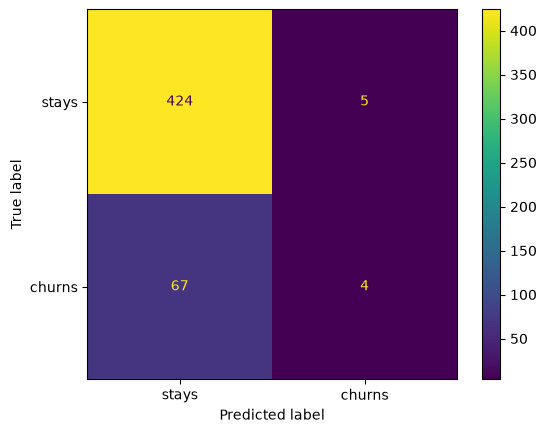

In [3]:
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

predicted = pipe.predict(X_test)
print(confusion_matrix(y_test, predicted))
ConfusionMatrixDisplay.from_predictions(y_test, predicted, display_labels=["stays", "churns"]);

## Precision, recall and F1

In [4]:
from sklearn.metrics import classification_report

print(classification_report(y_test, predicted, digits=3))

              precision    recall  f1-score   support

           0      0.864     0.988     0.922       429
           1      0.444     0.056     0.100        71

    accuracy                          0.856       500
   macro avg      0.654     0.522     0.511       500
weighted avg      0.804     0.856     0.805       500



Read the row for class 1, the churners. That is the job the model was built for.

## ROC-AUC
How well the model **ranks** customers, whatever the threshold.

In [5]:
from sklearn.metrics import roc_auc_score

probability = pipe.predict_proba(X_test)[:, 1]
print(round(roc_auc_score(y_test, probability), 2))

0.78


## Moving the threshold

In [6]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score

rows = []
for threshold in (0.5, 0.3, 0.2, 0.1):
    flagged = probability >= threshold
    rows.append({"threshold": threshold,
                 "precision": round(precision_score(y_test, flagged), 3),
                 "recall": round(recall_score(y_test, flagged), 3),
                 "flagged": int(flagged.sum())})
pd.DataFrame(rows)

,threshold,precision,recall,flagged
0,0.5,0.444,0.056,9
1,0.3,0.417,0.352,60
2,0.2,0.313,0.507,115
3,0.1,0.236,0.859,258


## Try it
A retention call costs $5 and a lost customer costs $200. Which threshold would you recommend, and why? Work out the cost of each row of the table.